In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("zomato.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head(5)

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [4]:
print("Rows and columns:", df.shape)

Rows and columns: (51717, 17)


In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [7]:
df.describe()

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000
50%,41.000000
75%,198.000000
max,16832.000000


In [8]:
df.dtypes

url                              str
address                          str
name                             str
online_order                     str
book_table                       str
rate                             str
votes                          int64
phone                            str
location                         str
rest_type                        str
dish_liked                       str
cuisines                         str
approx_cost(for two people)      str
reviews_list                     str
menu_item                        str
listed_in(type)                  str
listed_in(city)                  str
dtype: object

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
df_clean = df.copy()
df_clean.columns = df_clean.columns.str.strip()

columns_to_drop = ["url", "address", "phone", "reviews_list", "menu_item"]
df_clean.drop(columns=columns_to_drop, inplace=True, errors="ignore")

# Convert ratings such as '4.1/5' into numeric values
df_clean["rate"] = (
    df_clean["rate"].astype(str)
    .str.replace("/5", "", regex=False)
    .replace(["NEW", "-", "nan", "NaN"], np.nan)
)
df_clean["rate"] = pd.to_numeric(df_clean["rate"], errors="coerce")

# Convert approximate cost into numeric values
cost_column = "approx_cost(for two people)"
df_clean[cost_column] = (
    df_clean[cost_column].astype(str)
    .str.replace(",", "", regex=False)
)
df_clean[cost_column] = pd.to_numeric(df_clean[cost_column], errors="coerce")

df_clean["votes"] = pd.to_numeric(df_clean["votes"], errors="coerce")
df_clean.drop_duplicates(inplace=True)

print("Data transformation completed.")
print("Shape after transformation:", df_clean.shape)
df_clean.head()

Data transformation completed.
Shape after transformation: (51609, 12)


,name,online_order,book_table,rate,votes,location,rest_type,dish_liked,cuisines,approx_cost(for two people),listed_in(type),listed_in(city)
0,Jalsa,Yes,Yes,4.1,775,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800.0,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1,787,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800.0,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8,918,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800.0,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7,88,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300.0,Buffet,Banashankari
4,Grand Village,No,No,3.8,166,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600.0,Buffet,Banashankari


In [11]:
missing_before = df_clean.isnull().sum()
print("Missing values before handling:")
display(missing_before[missing_before > 0].sort_values(ascending=False))

Missing values before handling:


dish_liked                     28014
rate                           10019
approx_cost(for two people)      344
rest_type                        227
cuisines                          45
location                          21
dtype: int64

In [12]:
numerical_columns = df_clean.select_dtypes(include=np.number).columns

for column in numerical_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].mean())

categorical_columns = df_clean.select_dtypes(include=["object", "category"]).columns

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna("Unknown")

print("Missing values after handling:")
display(df_clean.isnull().sum())
print("Total missing values:", df_clean.isnull().sum().sum())

Missing values after handling:


C:\Users\Manvitha Acharya\AppData\Local\Temp\ipykernel_16292\846551142.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_clean.select_dtypes(include=["object", "category"]).columns


name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
location                       0
rest_type                      0
dish_liked                     0
cuisines                       0
approx_cost(for two people)    0
listed_in(type)                0
listed_in(city)                0
dtype: int64

Total missing values: 0


In [13]:
# Approximate cost per person, assuming the listed cost is for two people
df_clean["cost_per_person"] = df_clean[cost_column] / 2

df_clean["rating_category"] = pd.cut(
    df_clean["rate"],
    bins=[0, 2, 3, 4, 5],
    labels=["Poor", "Average", "Good", "Excellent"],
    include_lowest=True
)

df_clean[["name", "rate", "rating_category", cost_column, "cost_per_person"]].head()

,name,rate,rating_category,approx_cost(for two people),cost_per_person
0,Jalsa,4.1,Excellent,800.0,400.0
1,Spice Elephant,4.1,Excellent,800.0,400.0
2,San Churro Cafe,3.8,Good,800.0,400.0
3,Addhuri Udupi Bhojana,3.7,Good,300.0,150.0
4,Grand Village,3.8,Good,600.0,300.0


In [14]:
# Insight 1: Number of unique restaurant names
print("Number of unique restaurant names:", df_clean["name"].nunique())

Number of unique restaurant names: 8792


In [15]:
# Insight 2: Top 10 locations with the most restaurant listings
top_locations = df_clean["location"].value_counts().head(10)
display(top_locations)

location
BTM                      5109
HSR                      2521
Koramangala 5th Block    2502
JP Nagar                 2234
Whitefield               2140
Indiranagar              2075
Jayanagar                1926
Marathahalli             1843
Bannerghatta Road        1628
Bellandur                1283
Name: count, dtype: int64

In [16]:
# Insight 3: Ten highest-rated restaurant listings
top_rated = (
    df_clean[["name", "rate", "votes", "location"]]
    .sort_values(by=["rate", "votes"], ascending=[False, False])
    .head(10)
)
display(top_rated)

,name,rate,votes,location
49170,Byg Brewski Brewing Company,4.9,16832,Sarjapur Road
49627,Byg Brewski Brewing Company,4.9,16832,Sarjapur Road
50059,Byg Brewski Brewing Company,4.9,16832,Sarjapur Road
3921,Byg Brewski Brewing Company,4.9,16345,Sarjapur Road
4801,Byg Brewski Brewing Company,4.9,16345,Sarjapur Road
4944,Byg Brewski Brewing Company,4.9,16345,Sarjapur Road
37099,AB's - Absolute Barbecues,4.9,6490,BTM
21279,AB's - Absolute Barbecues,4.9,6452,BTM
19393,AB's - Absolute Barbecues,4.9,6404,BTM
21770,AB's - Absolute Barbecues,4.9,6404,BTM


In [17]:
# Insight 4: Average restaurant rating
print("Average restaurant rating:", round(df_clean["rate"].mean(), 2))

Average restaurant rating: 3.7


In [18]:
# Insight 5: Average approximate cost for two people
print("Average cost for two people:", round(df_clean[cost_column].mean(), 2))

Average cost for two people: 555.17


In [19]:
# Insight 6: Online ordering availability
display(df_clean["online_order"].value_counts())

online_order
Yes    30361
No     21248
Name: count, dtype: int64

In [20]:
# Insight 7: Most common restaurant types
display(df_clean["rest_type"].value_counts().head(10))

rest_type
Quick Bites           19096
Casual Dining         10309
Cafe                   3727
Delivery               2600
Dessert Parlor         2260
Takeaway, Delivery     2031
Casual Dining, Bar     1148
Bakery                 1140
Beverage Shop           865
Bar                     697
Name: count, dtype: int64

In [21]:
# Insight 8: Average rating by location (locations with at least 100 listings)
location_ratings = (
    df_clean.groupby("location")
    .agg(
        average_rating=("rate", "mean"),
        restaurant_count=("name", "count")
    )
)
location_ratings = location_ratings[location_ratings["restaurant_count"] >= 100]
display(location_ratings.sort_values("average_rating", ascending=False).head(10))

,average_rating,restaurant_count
location,,
Lavelle Road,4.105546,524
St. Marks Road,4.009095,352
Koramangala 3rd Block,3.983272,215
Koramangala 5th Block,3.983264,2502
Church Street,3.979158,566
Cunningham Road,3.894086,490
Koramangala 4th Block,3.880851,1017
Residency Road,3.845104,672
MG Road,3.837094,917


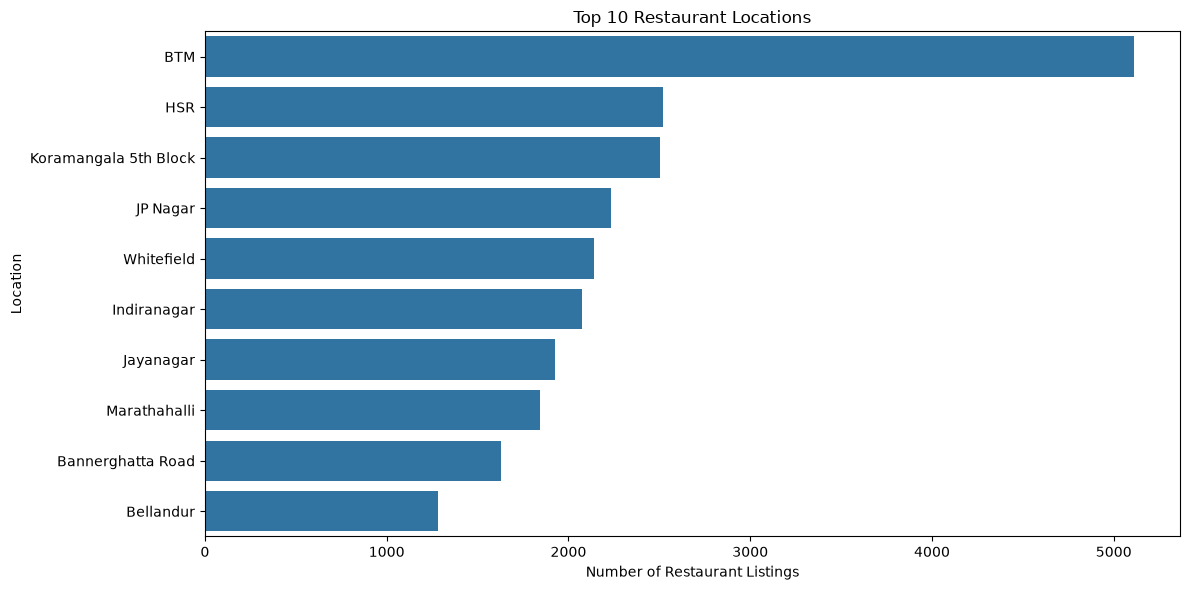

In [22]:
# Chart 1: Top 10 restaurant locations
plt.figure(figsize=(12, 6))
sns.barplot(x=top_locations.values, y=top_locations.index)
plt.title("Top 10 Restaurant Locations")
plt.xlabel("Number of Restaurant Listings")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

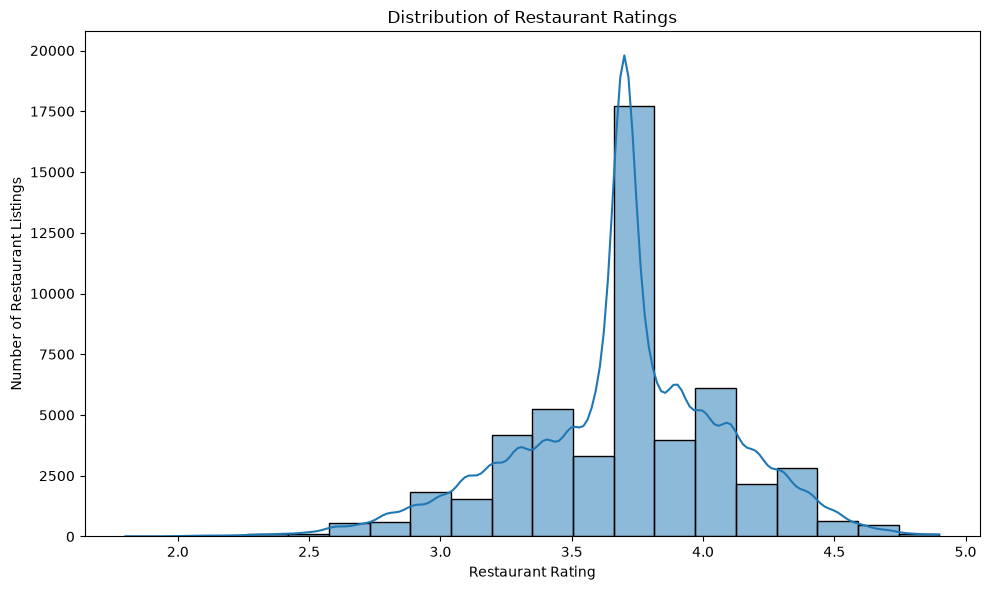

In [23]:
# Chart 2: Distribution of restaurant ratings
plt.figure(figsize=(10, 6))
sns.histplot(data=df_clean, x="rate", bins=20, kde=True)
plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Restaurant Rating")
plt.ylabel("Number of Restaurant Listings")
plt.tight_layout()
plt.show()

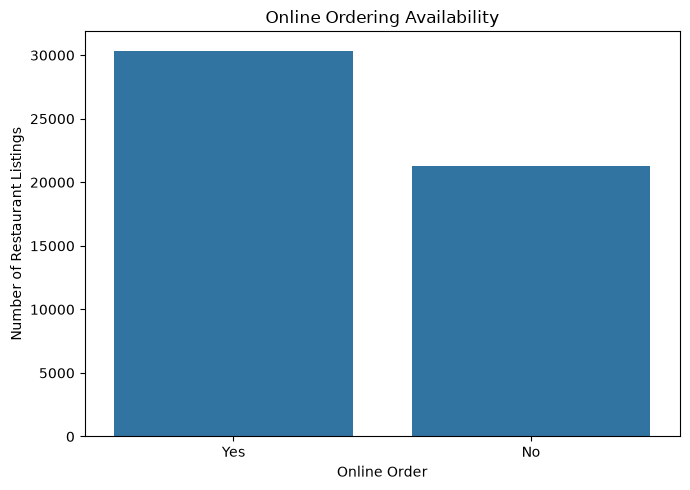

In [24]:
# Chart 3: Online ordering availability
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="online_order")
plt.title("Online Ordering Availability")
plt.xlabel("Online Order")
plt.ylabel("Number of Restaurant Listings")
plt.tight_layout()
plt.show()

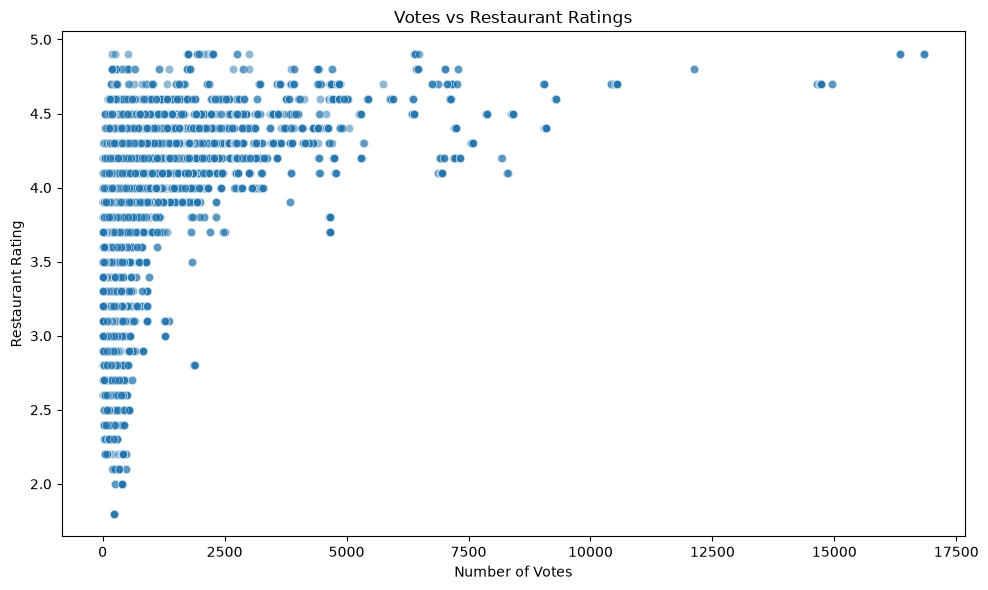

In [25]:
# Chart 4: Votes versus restaurant ratings
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x="votes", y="rate", alpha=0.5)
plt.title("Votes vs Restaurant Ratings")
plt.xlabel("Number of Votes")
plt.ylabel("Restaurant Rating")
plt.tight_layout()
plt.show()

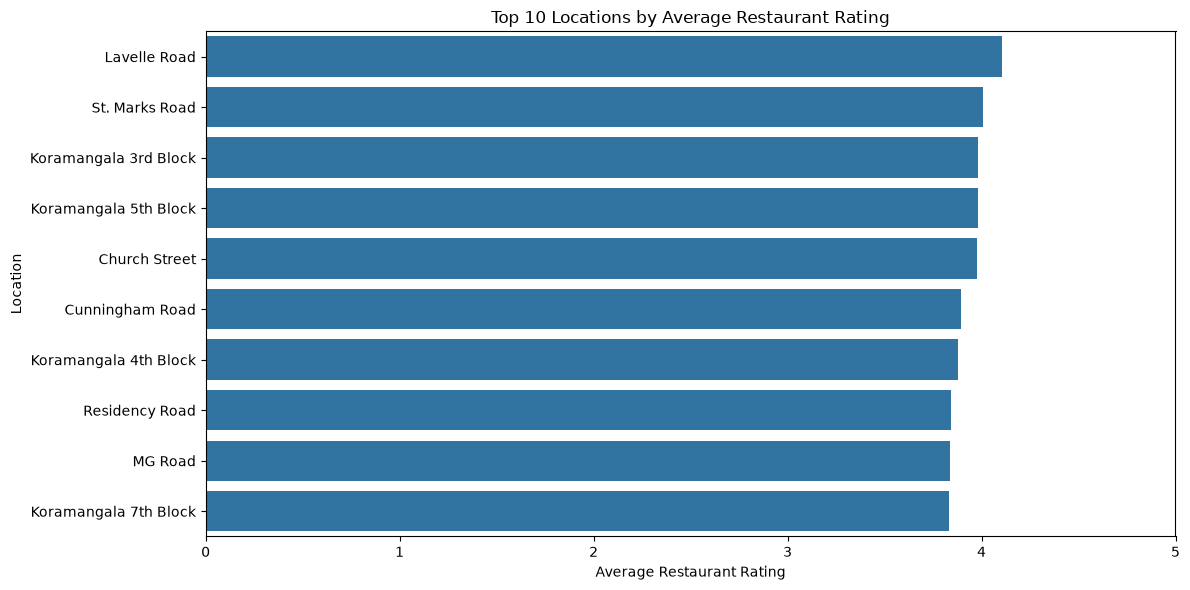

In [26]:
# Chart 5: Top 10 locations by average rating
top_rating_locations = location_ratings.sort_values("average_rating", ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_rating_locations["average_rating"], y=top_rating_locations.index)
plt.title("Top 10 Locations by Average Restaurant Rating")
plt.xlabel("Average Restaurant Rating")
plt.ylabel("Location")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

In [27]:
print("Final cleaned dataset shape:", df_clean.shape)

print("First five rows of the cleaned dataset:")
display(df_clean.head())

print("Missing values in the final dataset:")
display(df_clean.isnull().sum())

print("Total missing values:", df_clean.isnull().sum().sum())
print("DATA ANALYSIS COMPLETED!")

Final cleaned dataset shape: (51609, 14)
First five rows of the cleaned dataset:


,name,online_order,book_table,rate,votes,location,rest_type,dish_liked,cuisines,approx_cost(for two people),listed_in(type),listed_in(city),cost_per_person,rating_category
0,Jalsa,Yes,Yes,4.1,775,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800.0,Buffet,Banashankari,400.0,Excellent
1,Spice Elephant,Yes,No,4.1,787,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800.0,Buffet,Banashankari,400.0,Excellent
2,San Churro Cafe,Yes,No,3.8,918,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800.0,Buffet,Banashankari,400.0,Good
3,Addhuri Udupi Bhojana,No,No,3.7,88,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300.0,Buffet,Banashankari,150.0,Good
4,Grand Village,No,No,3.8,166,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600.0,Buffet,Banashankari,300.0,Good


Missing values in the final dataset:


name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
location                       0
rest_type                      0
dish_liked                     0
cuisines                       0
approx_cost(for two people)    0
listed_in(type)                0
listed_in(city)                0
cost_per_person                0
rating_category                0
dtype: int64

Total missing values: 0
DATA ANALYSIS COMPLETED!
